# 124 · LoRA from scratch: low-rank updates, the α/r scale, merging, and why it works

In [1]:
import math, time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=8, alpha=16, dropout=0.0):
        super().__init__()
        self.base, self.r, self.scale = base, r, alpha / r
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + self.scale * (self.drop(x) @ self.A.T @ self.B.T)
    def merged(self):
        m = nn.Linear(self.base.in_features, self.base.out_features)
        m.weight.data = self.base.weight.data + self.scale * self.B.data @ self.A.data; m.bias.data = self.base.bias.data.clone()
        return m

def trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [2]:
torch.manual_seed(0)
d = 512
base = nn.Linear(d, d)
true_delta = torch.randn(d, 4) @ torch.randn(4, d) * 0.05
target = nn.Linear(d, d); target.weight.data = base.weight.data + true_delta; target.bias.data = base.bias.data.clone()
X = torch.randn(4096, d)
with torch.no_grad():
    Y = target(X)
print("singular values of the 'fine-tuning' update ΔW:", torch.linalg.svdvals(true_delta)[:8].numpy().round(2), "-> rank 4")

singular values of the 'fine-tuning' update ΔW: [27.91 25.92 25.4  23.91  0.    0.    0.    0.  ] -> rank 4


rank  1: trainable   1,024 of 262,656 (0.4%), final MSE 3.36e+00


rank  2: trainable   2,048 of 262,656 (0.8%), final MSE 2.26e+00


rank  4: trainable   4,096 of 262,656 (1.6%), final MSE 1.51e-08


rank  8: trainable   8,192 of 262,656 (3.1%), final MSE 2.21e-02


rank 32: trainable  32,768 of 262,656 (12.5%), final MSE 5.12e-04


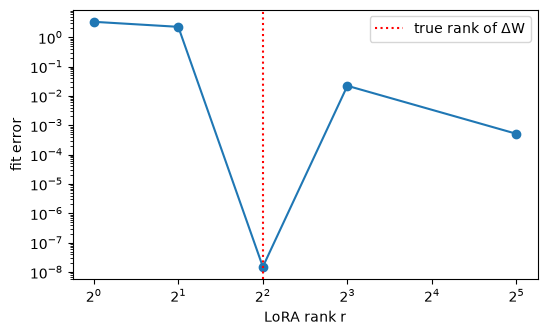

In [3]:
results = {}
for r in [1, 2, 4, 8, 32]:
    lora = LoRALinear(nn.Linear(d, d), r=r, alpha=2 * r); lora.base.load_state_dict(base.state_dict())
    opt = torch.optim.Adam([lora.A, lora.B], 1e-2)
    for step in range(1500):
        idx = torch.randint(0, len(X), (256,))
        loss = ((lora(X[idx]) - Y[idx]) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    results[r] = loss.item()
    print(f"rank {r:2d}: trainable {trainable(lora):7,d} of {d * d + d:,d} ({trainable(lora) / (d * d + d):.1%}), final MSE {loss.item():.2e}")
plt.figure(figsize=(6, 3.5)); plt.semilogy(list(results), list(results.values()), "o-"); plt.axvline(4, c="r", ls=":", label="true rank of ΔW")
plt.xscale("log", base=2); plt.xlabel("LoRA rank r"); plt.ylabel("fit error"); plt.legend(); plt.show()

In [4]:
lora = LoRALinear(nn.Linear(d, d), r=4, alpha=8); lora.base.load_state_dict(base.state_dict())
print("B is initialized to zero, so a fresh adapter changes nothing:", torch.allclose(lora(X[:5]), base(X[:5])))
opt = torch.optim.Adam([lora.A, lora.B], 1e-2)
for step in range(1500):
    idx = torch.randint(0, len(X), (256,)); loss = ((lora(X[idx]) - Y[idx]) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
merged = lora.merged()
print("merged W + (α/r)·BA gives identical outputs:", torch.allclose(merged(X[:100]), lora(X[:100]), atol=1e-5), "-> zero inference overhead after merging")

B is initialized to zero, so a fresh adapter changes nothing: True


merged W + (α/r)·BA gives identical outputs: True -> zero inference overhead after merging


In [5]:
for n_params, name in [(7.5e9, "OpenVLA-7B"), (3.3e9, "π0"), (0.29e9, "MiniVLA")]:
    full = n_params * (2 + 2 + 12)
    print(f"{name:10s} full fine-tune (bf16 weights+grads + fp32 Adam states): ~{full / 1e9:5.0f} GB | LoRA (frozen bf16 weights + ~1% trainable): ~{n_params * 2 / 1e9 + 0.01 * n_params * 16 / 1e9:4.1f} GB | QLoRA (4-bit base): ~{n_params * 0.5 / 1e9 + 0.01 * n_params * 16 / 1e9:4.1f} GB")

OpenVLA-7B full fine-tune (bf16 weights+grads + fp32 Adam states): ~  120 GB | LoRA (frozen bf16 weights + ~1% trainable): ~16.2 GB | QLoRA (4-bit base): ~ 5.0 GB
π0         full fine-tune (bf16 weights+grads + fp32 Adam states): ~   53 GB | LoRA (frozen bf16 weights + ~1% trainable): ~ 7.1 GB | QLoRA (4-bit base): ~ 2.2 GB
MiniVLA    full fine-tune (bf16 weights+grads + fp32 Adam states): ~    5 GB | LoRA (frozen bf16 weights + ~1% trainable): ~ 0.6 GB | QLoRA (4-bit base): ~ 0.2 GB
